<div style="background:#E7E8DC;border-top:4px solid #B0B187;padding:12px 16px;color:#292722;font-family:monospace;font-size:12px;letter-spacing:0.06em;">
GEOSTATISTICS LESSONS · ESTIMATION · COMPANION NOTEBOOK
</div>

# Collocated Cokriging

**Matthew Samson and Clayton Deutsch**

Notebook published: 2020

[Read the lesson](https://geostatisticslessons.com/lessons/collocatedcokriging) · [Notebook guide](README.md)

## Learning Objectives

- Review cokriging.
- Understand the development of the Markov Models.
- Demonstrate (intrinsic) collocated cokriging with Markov model II
- Understand a workflow for collocated cokriging.

## Overview

This notebook implements the Geostatistics Lesson on Collocated Cokriging. This code is provided for educational purposes and should be reviewed jointly with the lesson <a href="https://geostatisticslessons.com/lessons/collocatedcokriging">Collocated Cokriging</a>.

In [1]:
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import distance_matrix
from sklearn.metrics import mean_squared_error
from tqdm.auto import tqdm

np.set_printoptions(precision=3)

%matplotlib inline

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "text.color": "#292722",
        "axes.labelcolor": "#292722",
        "axes.edgecolor": "#292722",
        "font.size": 11,
    }
)

# Start the kernel from the repository root, alongside the data/ folder.
DATA_DIR = Path.cwd() / "data"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Start this notebook from the repository root, which contains data/."
    )

print(f"Python {platform.python_version()}")
print(
    " · ".join(
        f"{name} {version(name)}"
        for name in ["numpy", "pandas", "matplotlib", "scipy", "scikit-learn"]
    )
)

Python 3.12.7
numpy 1.26.4 · pandas 2.1.4 · matplotlib 3.9.2 · scipy 1.14.1 · scikit-learn 1.5.2


## Import Data

In [2]:
datafl = pd.read_csv(DATA_DIR / "collocatedcokriging_cluster1.out")
datafl_sec = pd.read_csv(DATA_DIR / "collocatedcokriging_ydata.out")
truth = pd.read_csv(DATA_DIR / "collocatedcokriging_true.out")
x = np.asarray(pd.read_csv(DATA_DIR / "collocatedcokriging_x.out")).reshape(
    len(datafl_sec)
)
y = np.asarray(pd.read_csv(DATA_DIR / "collocatedcokriging_y.out")).reshape(
    len(datafl_sec)
)

In [3]:
print("Primary Data")
datafl.describe()

Primary Data


,X,Y,Primary,Secondary
count,64.000000,64.000000,64.000000,64.000000
mean,50.000000,50.000000,-0.424719,-0.197425
std,28.867513,28.867513,1.032475,0.912744
min,6.250000,6.250000,-2.623800,-2.020500
25%,28.125000,28.125000,-1.015100,-0.767850
50%,50.000000,50.000000,-0.387650,-0.224450
75%,71.875000,71.875000,0.176975,0.254700
max,93.750000,93.750000,2.148700,1.889200


In [4]:
print("Secondary Data")
datafl_sec.describe()

Secondary Data


,X,Y,Secondary
count,10000.000000,10000.000000,10000.000000
mean,50.000000,50.000000,-0.250033
std,28.867513,28.867513,0.936804
min,0.500000,0.500000,-3.272810
25%,25.250000,25.250000,-0.817387
50%,50.000000,50.000000,-0.183005
75%,74.750000,74.750000,0.327833
max,99.500000,99.500000,2.781670


### Maps of the Data

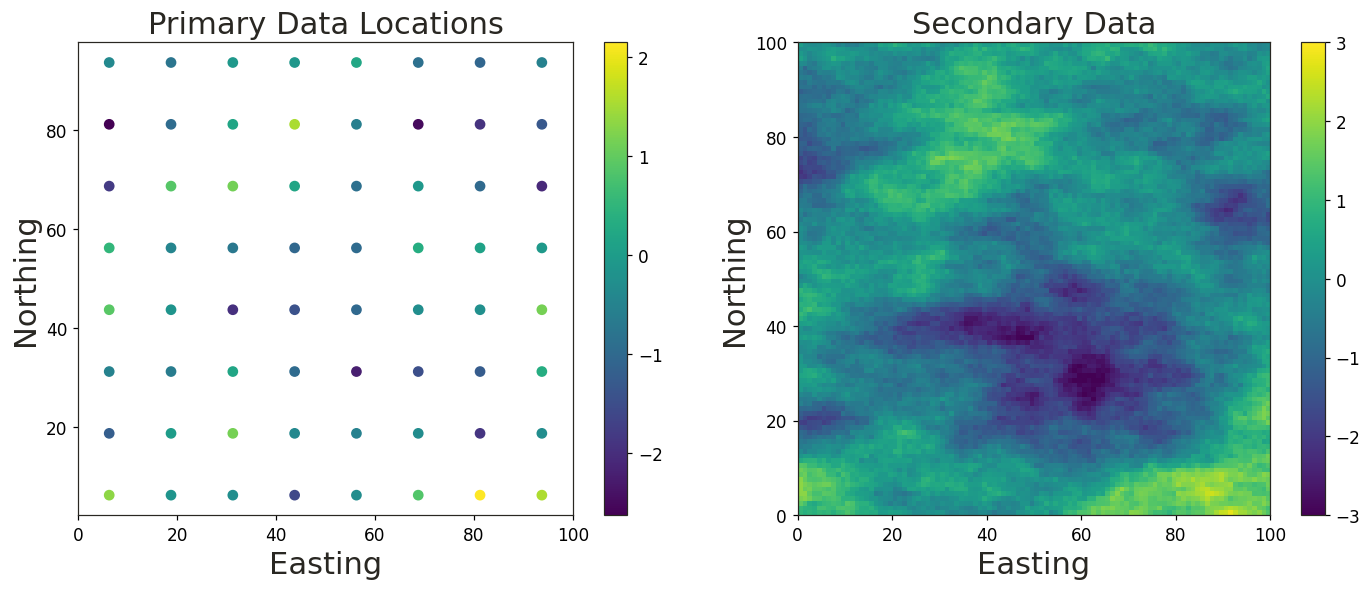

In [5]:
vlim = (-3, 3)
f, ax = plt.subplots(1, 2, figsize=(13, 5.5))
XMIN, XMAX = 0, 100
YMIN, YMAX = 0, 100
SMIN, SMAX = -3, 3
gridd = pd.DataFrame()
gridd["Y"] = y
gridd["X"] = x
gridd["Estimate"] = datafl_sec["Secondary"]
gridded = np.reshape(
    gridd.sort_values(by=["Y", "X"], axis=0, ascending=True)["Estimate"].values,
    [100, 100],
    order="C",
)
img0 = ax[0].scatter(datafl["X"], datafl["Y"], c=datafl["Primary"].values)
ax[0].set_title("Primary Data Locations", size=20)
ax[0].set_xlabel("Easting", size=20)
ax[0].set_ylabel("Northing", size=20)
ax[0].axis("equal")
ax[0].set(xlim=(0, 100), ylim=(0, 100))
img1 = ax[1].imshow(
    gridded,
    origin="lower",
    extent=[XMIN, XMAX, YMIN, YMAX],
    aspect="equal",
    interpolation="none",
    vmin=SMIN,
    vmax=SMAX,
    cmap="viridis",
)
ax[1].set_xlabel("Easting", size=20)
ax[1].set_ylabel("Northing", size=20)
ax[1].set_title("Secondary Data", size=20)
f.colorbar(img0, ax=ax[0])
f.colorbar(img1, ax=ax[1])
plt.tight_layout()

### Check the Distribution and Correlation of the Data

Histogram labels show empirical variances with divisor $n$ (NumPy `ddof=0`). The unit-sill covariance model below remains unchanged.

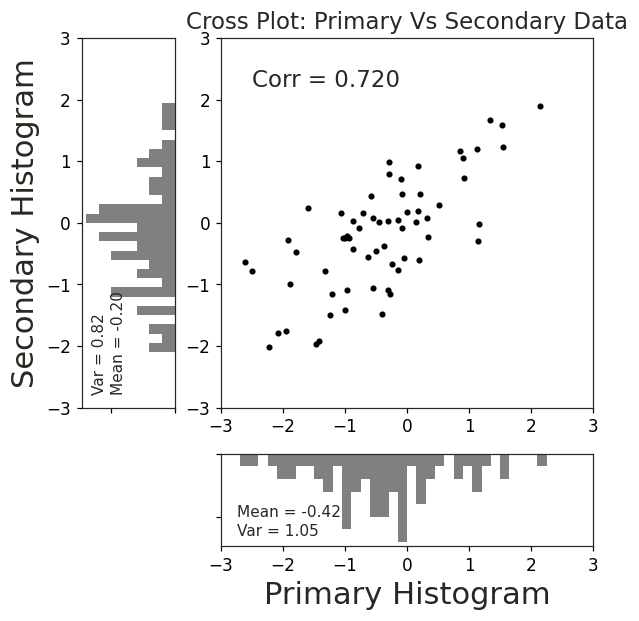

In [6]:
# Set up the axes with gridspec
corr = np.corrcoef(datafl["Primary"], datafl["Secondary"])[0, 1]
vlim = (-3, 3)
fig = plt.figure(figsize=(6, 6))
grid = plt.GridSpec(4, 4, hspace=0.5, wspace=0.5)
main_ax = fig.add_subplot(grid[:-1, 1:])
y_hist = fig.add_subplot(grid[:-1, 0], xticklabels=[], sharey=main_ax)
x_hist = fig.add_subplot(grid[-1, 1:], yticklabels=[], sharex=main_ax)

# scatter points on the main axes
main_ax.plot(datafl["Primary"], datafl["Secondary"], "ok", markersize=3)
main_ax.set_xlim(vlim)
main_ax.set_ylim(vlim)
main_ax.set_title("Cross Plot: Primary Vs Secondary Data", size=15)
main_ax.text(
    -2.5,
    2.2,
    "Corr = {:.3f}".format(np.corrcoef(datafl["Primary"], datafl["Secondary"])[0, 1]),
    size=15,
)

# histogram on the attached axes
x_hist.hist(
    datafl["Primary"],
    40,
    histtype="stepfilled",
    label="Primary",
    orientation="vertical",
    color="gray",
    range=vlim,
)
x_hist.set_xlabel("Primary Histogram", size=20)
x_hist.invert_yaxis()
x_hist.text(-2.75, 5, "Mean = {:.2f}".format(np.average(datafl["Primary"])), size=10)
x_hist.text(-2.75, 6.5, f"Var = {np.var(datafl['Primary'], ddof=0):.2f}", size=10)


y_hist.hist(
    datafl["Secondary"],
    40,
    histtype="stepfilled",
    orientation="horizontal",
    color="gray",
    range=vlim,
)
y_hist.set_ylabel("Secondary Histogram", size=20)
y_hist.invert_xaxis()
y_hist.text(
    5,
    -2.75,
    "Mean = {:.2f}".format(np.average(datafl["Secondary"])),
    rotation=90,
    size=10,
)
y_hist.text(
    6.5, -2.75, f"Var = {np.var(datafl['Secondary'], ddof=0):.2f}", rotation=90, size=10
)
np.testing.assert_allclose(
    [np.var(datafl["Primary"], ddof=0), np.var(datafl["Secondary"], ddof=0)],
    [1.0493488230859376, 0.8200846971874999],
)

## Correlograms

## Initialize Correlogram Types

In [7]:
def covar(t, d, r):
    h = d / r
    if t == 1:  # Spherical
        c = 1 - h * (1.5 - 0.5 * np.square(h))
        c[h > 1] = 0
    elif t == 2:  # Exponential
        c = np.exp(-3 * h)
    elif t == 3:  # Gaussian
        c = np.exp(-3 * np.square(h))
    return c

## Fit Experimental Correlogram Points

Experimental variogram points were pre-calculated.

In [8]:
varcalcfl_1 = pd.read_csv(DATA_DIR / "collocatedcokriging_varcalc_cluster.out")
varcalcfl_2 = pd.read_csv(DATA_DIR / "collocatedcokriging_varcalc_ydata.out")
varcalcfl_3 = pd.read_csv(DATA_DIR / "collocatedcokriging_varcalc_cross.out")

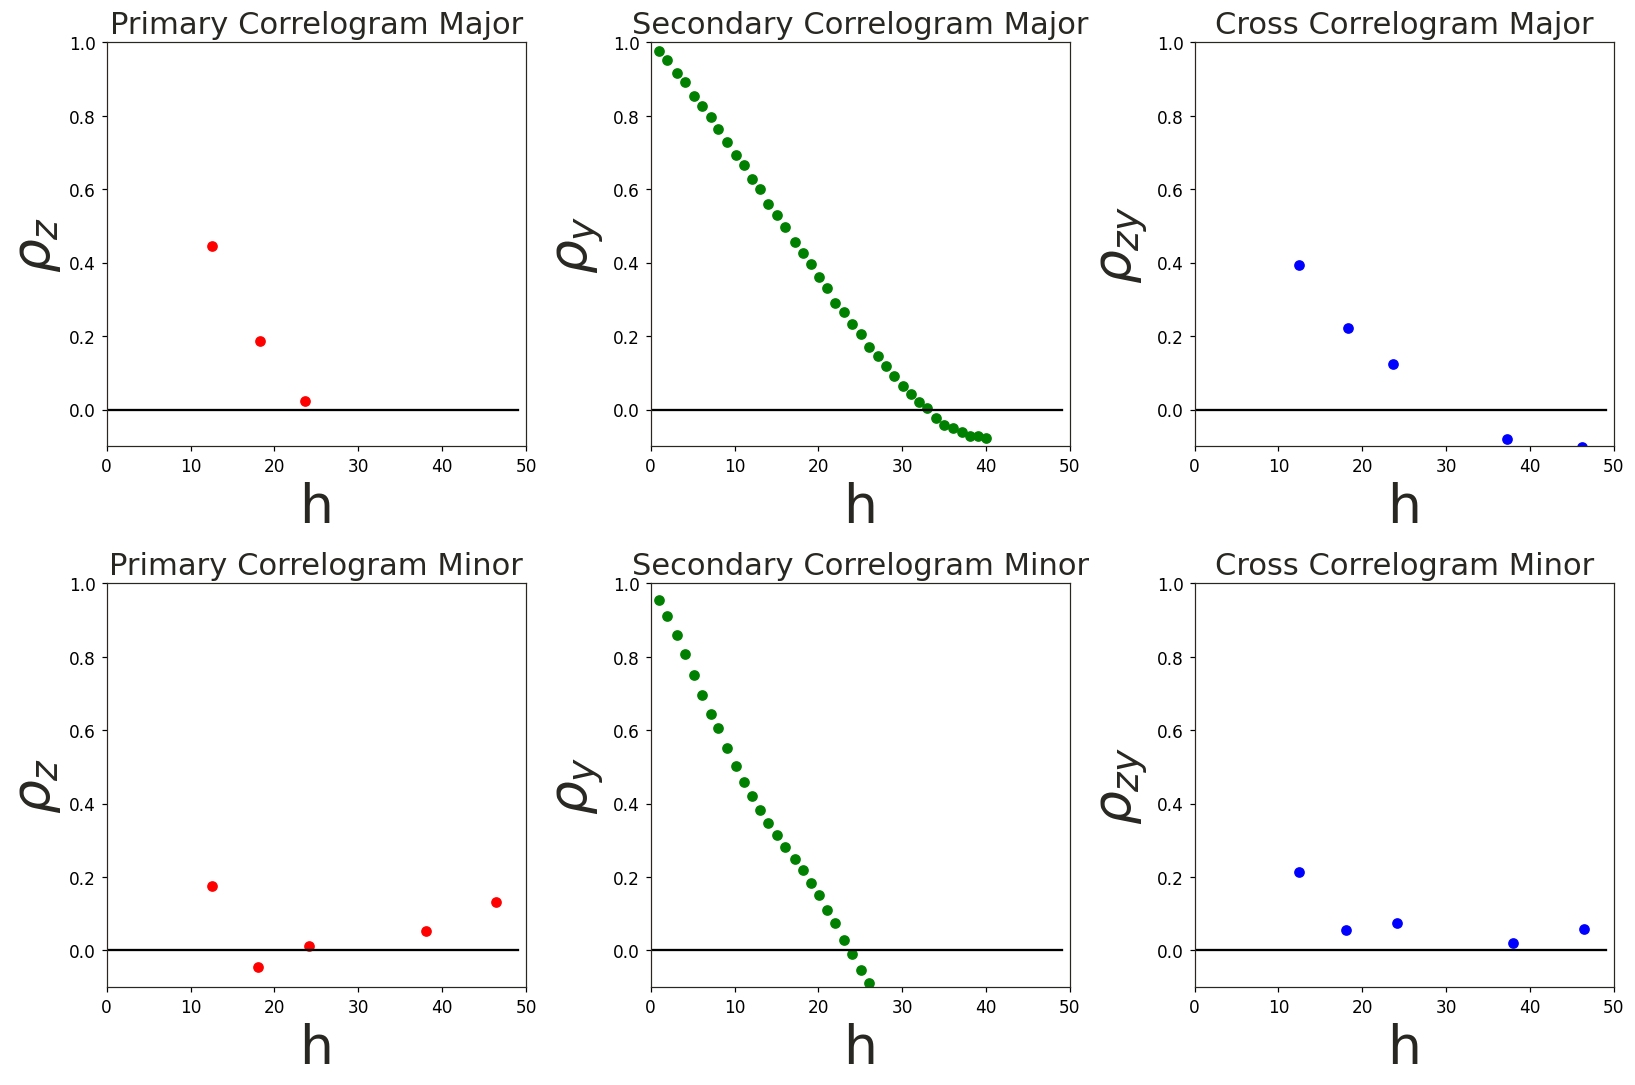

In [9]:
ones = np.zeros(shape=(50))
Cross_ones = np.zeros(shape=(50))
H = np.zeros(shape=(50))
Corr_labels = [
    "Primary Correlogram",
    "Secondary Correlogram",
    "Cross Correlogram",
]
Directions = ["Major", "Minor"]
colors = ["Red", "Green", "Blue"]
labels_2 = ["$\u03c1_{z}$", "$\u03c1_{y}$", "$\u03c1_{zy}$"]
Sill_vals = [1, 1, corr]
for h in range(1, 50):
    H[h] = h
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for i in range(0, 3):
    var = locals()[f"varcalcfl_{i + 1}"]
    for j in range(0, 2):
        axes[j, i].plot(
            var["Lag Distance"][var["Variogram Index"] == (j + 1)],
            Sill_vals[i] - var["Variogram Value"][var["Variogram Index"] == (j + 1)],
            "o",
            color=colors[i],
        )
        axes[j, i].set_ylabel(labels_2[i], size=35)
        axes[j, i].plot(H, ones, color="Black")
        axes[j, i].set_xlabel("h", size=35)
        axes[j, i].set_title(Corr_labels[i] + " " + Directions[j], size=20)
plt.setp(axes, xlim=(0, 50), ylim=(-0.1, 1))
plt.tight_layout()

### Calculate Rotation Matrix

Using a major direction of 90 degrees east of north, this is fairly obvious from the primary and secondary data. See https://geostatisticslessons.com/lessons/anglespecification

In [10]:
def Rot_Mat(Azimuth, a_max, a_min):
    theta = (Azimuth / 180.0) * np.pi
    Rot_Mat = np.dot(
        np.array([[1 / a_max, 0], [0, 1 / a_min]]),
        np.array(
            [
                [np.cos(theta), np.sin(theta)],
                [-np.sin(theta), np.cos(theta)],
            ]
        ),
    )
    return Rot_Mat

### Primary Correlogram

In [11]:
# h1 = Set of points X,Y
# h2 = Set of points X,Y
# k = 0 used for calculating the distance between the same points
# k = 1 used for calculating distance between different points
# k = 2 used for plotting in the major direction
# k = 3 used for plotting in the minor direction
def C_Z(h1, h2, k):
    nstruct = 1
    vtype = [3]
    a_max = [24]
    a_min = [16]
    Azimuth = 90
    cc = [1]
    c = 0
    for i in range(nstruct):
        Q1 = h1.copy()
        Q2 = h2.copy()
        if k == 0:
            d = distance_matrix(
                np.matmul(Q1, Rot_Mat(Azimuth, a_max[i], a_min[i])),
                np.matmul(Q2, Rot_Mat(Azimuth, a_max[i], a_min[i])),
            )
        elif k == 1:
            d = np.sqrt(
                np.square(
                    (np.matmul(Q1, Rot_Mat(Azimuth, a_max[i], a_min[i])))
                    - np.tile(
                        (np.matmul(Q2, Rot_Mat(Azimuth, a_max[i], a_min[i]))),
                        (k, 1),
                    )
                ).sum(axis=1)
            )
            d = np.asarray(d).reshape(len(d))
        elif k == 2:
            d = Q1 / a_max[i]
        elif k == 3:
            d = Q1 / a_min[i]
        c = c + covar(vtype[i], d, 1) * cc[i]
    return c

### Secondary Correlogram

In [12]:
# h1 = Set of points X,Y
# h2 = Set of points X,Y
# k = 0 used for calculating the distance between the same points
# k = 1 used for calculating distance between different points
# k = 2 used for plotting in the major direction
# k = 3 used for plotting in the minor direction
def C_Y(h1, h2, k):
    nstruct = 2
    vtype = [1, 3]
    a_max = [42, 43]
    a_min = [28.5, 30]
    Azimuth = 90
    cc = [0.9, 0.1]
    c = 0
    for i in range(nstruct):
        Q1 = h1.copy()
        Q2 = h2.copy()
        if k == 0:
            d = distance_matrix(
                np.matmul(Q1, Rot_Mat(Azimuth, a_max[i], a_min[i])),
                np.matmul(Q2, Rot_Mat(Azimuth, a_max[i], a_min[i])),
            )
        elif k == 1:
            # Match the Euclidean metric used by the pairwise covariance matrix.
            delta = (Q1 - Q2) @ Rot_Mat(Azimuth, a_max[i], a_min[i])
            d = np.linalg.norm(delta, axis=1)
        elif k == 2:
            d = Q1 / a_max[i]
        elif k == 3:
            d = Q1 / a_min[i]
        c = c + covar(vtype[i], d, 1) * cc[i]
    return c

### Scaling Correlogram

In [13]:
# h1 = Set of points X,Y
# h2 = Set of points X,Y
# k = 0 used for calculating the distance between the same points
# k = 1 used for calculating distance between different points
# k = 2 used for plotting in the major direction
# k = 3 used for plotting in the minor direction
def C_r(h1, h2, k):
    nstruct = 1
    vtype = [3]
    a_max = [18]
    a_min = [13]
    Azimuth = 90
    cc = [1]
    c = 0
    for i in range(nstruct):
        Q1 = h1.copy()
        Q2 = h2.copy()
        if k == 0:
            d = distance_matrix(
                np.matmul(Q1, Rot_Mat(Azimuth, a_max[i], a_min[i])),
                np.matmul(Q2, Rot_Mat(Azimuth, a_max[i], a_min[i])),
            )
        elif k == 1:
            d = np.sqrt(
                np.square(
                    (np.matmul(Q1, Rot_Mat(Azimuth, a_max[i], a_min[i])))
                    - np.tile(
                        (np.matmul(Q2, Rot_Mat(Azimuth, a_max[i], a_min[i]))),
                        (k, 1),
                    )
                ).sum(axis=1)
            )
            d = np.asarray(d).reshape(len(d))
        elif k == 2:
            d = Q1 / a_max[i]
        elif k == 3:
            d = Q1 / a_min[i]
        c = c + covar(vtype[i], d, 1) * cc[i]
    return c

### C_Z Correlogram MM2

In [14]:
# h1 = Set of points X,Y
# h2 = Set of points X,Y
# Corr = correlation between primary and secondary data
# k = 0 used for calculating the distance between the same points
# k = 1 used for calculating distance between different points
# k = 2 used for plotting in the major direction
# k = 3 used for plotting in the minor direction
def C_Z_MM2(h1, h2, k, corr):
    return (C_Y(h1, h2, k) * corr**2) + ((1 - corr**2) * C_r(h1, h2, k))

### Plots Correlogram Models

In [15]:
# Define some matrices for storing variogram values
cy = np.zeros(shape=(51))
cz_True = np.zeros(shape=(51))
cr = np.zeros(shape=(51))
cz = np.zeros(shape=(51))
czy = np.zeros(shape=(51))
H = np.zeros(shape=(51))
ones = np.zeros(shape=(51))
cy_LMC = np.zeros(shape=(51))
cz_LMC = np.zeros(shape=(51))
czy_LMC = np.zeros(shape=(51))
# Define some plotting labels
labels_1 = [r"$\hat{\rho}_{z}$", r"$\hat{\rho}_{y}$", r"$\hat{\rho}_{zy}$"]
labels_MM = [
    "$\u03c1_{z_{Model}}$",
    "$\u03c1_{y_{Model}}$",
    "$\u03c1_{z_{MMII}}$",
]
labels_lmc = [
    "$\u03c1_{z_{LMC}}$",
    "$\u03c1_{y_{LMC}}$",
    "$\u03c1_{zy_{LMC}}$",
]
colors_lmc = ["Orange", "Yellow", "Grey"]

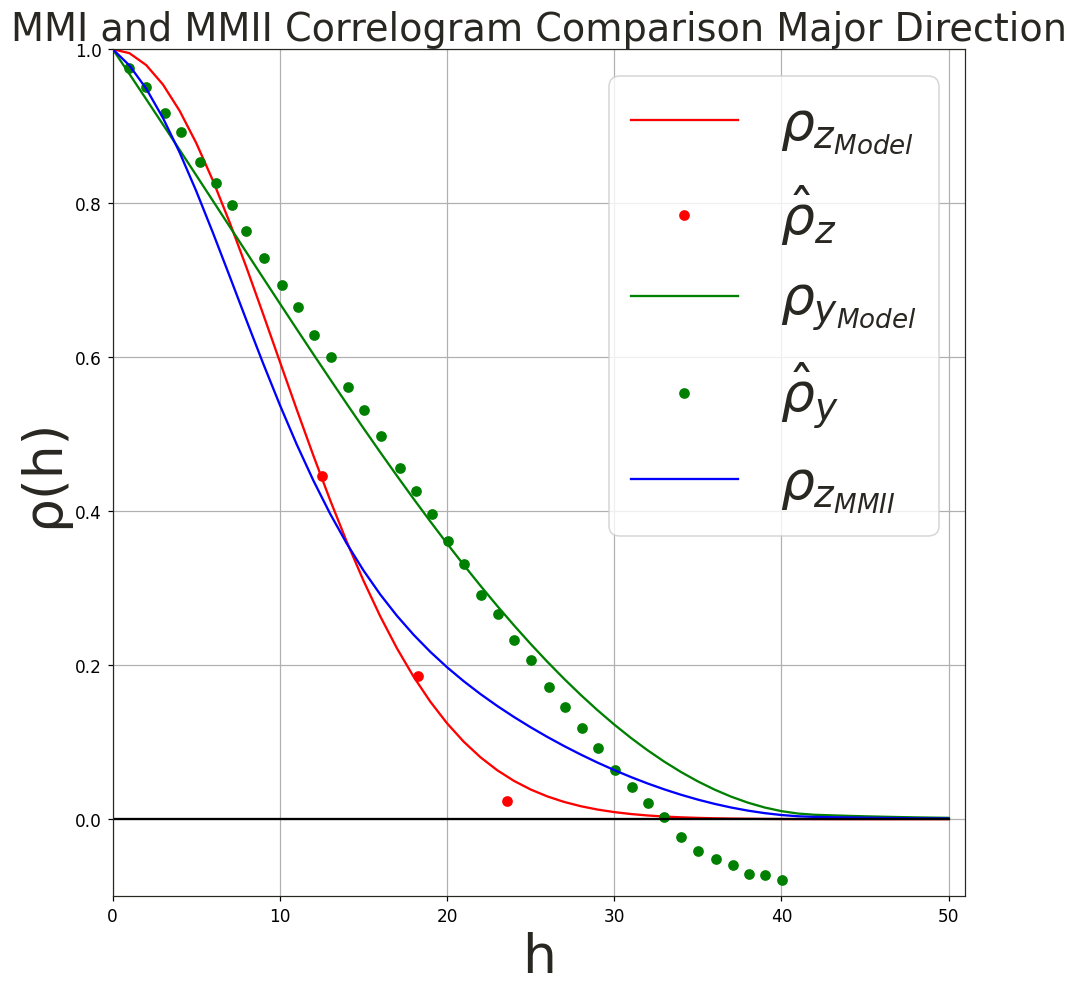

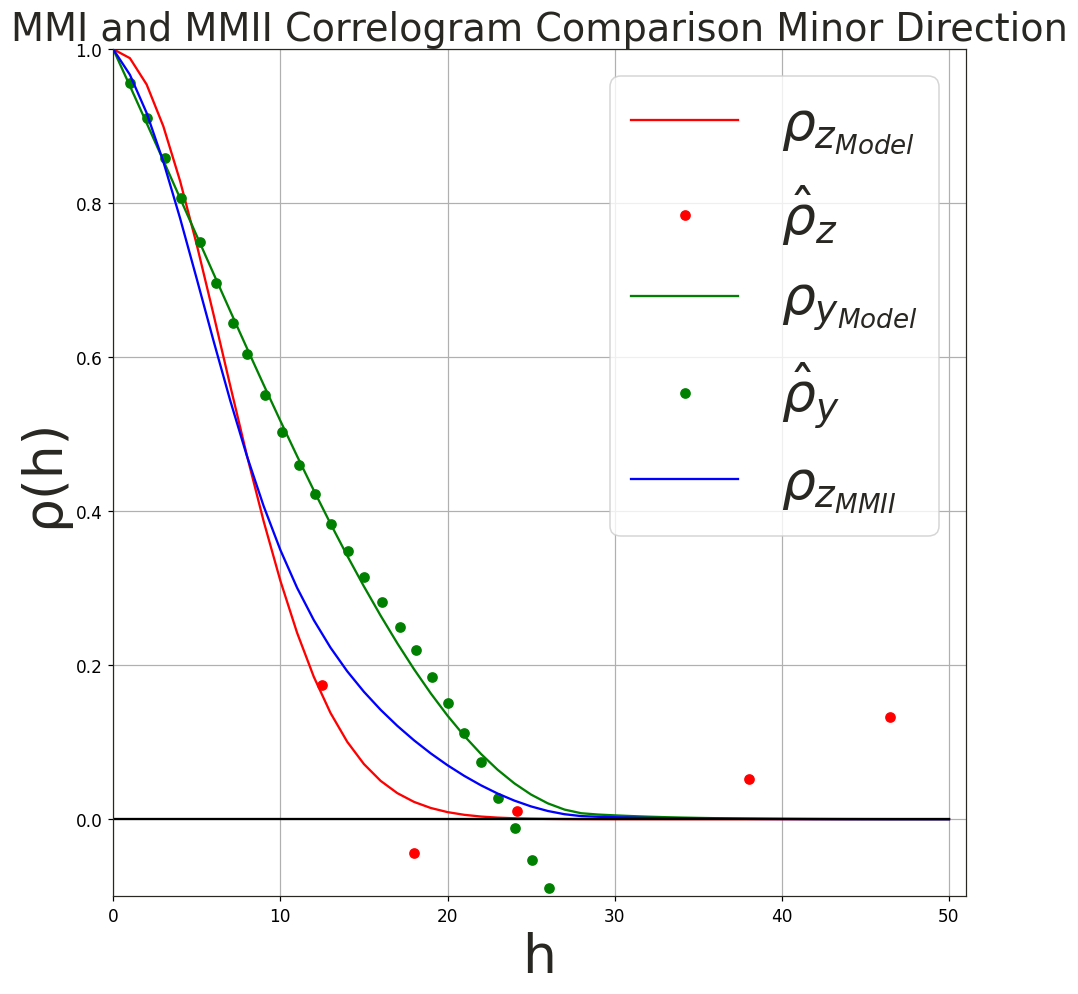

In [16]:
varg_type = 2  # See Correlogram Functions
for Dir in Directions:
    for h in range(0, 51):
        cy[h] = C_Y(
            np.array([h], dtype=float), np.array([h], dtype=float), varg_type
        ).item()
        cz_True[h] = C_Z(
            np.array([h], dtype=float), np.array([h], dtype=float), varg_type
        ).item()
        cz[h] = C_Z_MM2(
            np.array([h], dtype=float), np.array([h], dtype=float), varg_type, corr
        ).item()
        cr[h] = C_r(
            np.array([h], dtype=float), np.array([h], dtype=float), varg_type
        ).item()
        H[h] = h
    MM_vargs = [cz_True, cy, cz]
    fig, axes = plt.subplots(1, 1, figsize=(10, 10))
    for i in range(0, 3):
        axes.plot(H, MM_vargs[i], color=colors[i], label=labels_MM[i])
        if (i + 1) < 3:
            var = locals()[f"varcalcfl_{i + 1}"]
            axes.plot(
                var["Lag Distance"][var["Variogram Index"] == (varg_type - 1)],
                Sill_vals[i]
                - var["Variogram Value"][var["Variogram Index"] == (varg_type - 1)],
                "o",
                color=colors[i],
                label=labels_1[i],
            )

    axes.plot(H, ones, color="Black")
    axes.grid()
    plt.xlim(0, 51)
    plt.ylim(-0.1, 1)
    plt.ylabel("\u03c1(h)", size=35)
    plt.xlabel("h", size=35)
    plt.title(
        f"MMI and MMII Correlogram Comparison {Dir} Direction",
        size=25,
    )
    axes.legend(loc="best", prop={"size": 35})
    varg_type = varg_type + 1

### Cross Correlogram

In [17]:
def C_ZY(h1, h2, k, corr):
    nstruct = 1
    vtype = [1]
    a_max = [45]
    a_min = [30]
    Azimuth = 90
    cc = [corr]
    c = 0
    for i in range(nstruct):
        Q1 = h1.copy()
        Q2 = h2.copy()
        if k == 0:
            d = distance_matrix(
                np.matmul(Q1, Rot_Mat(Azimuth, a_max[i], a_min[i])),
                np.matmul(Q2, Rot_Mat(Azimuth, a_max[i], a_min[i])),
            )
        elif k == 1:
            d = np.sqrt(
                np.square(
                    (np.matmul(Q1, Rot_Mat(Azimuth, a_max[i], a_min[i])))
                    - np.tile(
                        (np.matmul(Q2, Rot_Mat(Azimuth, a_max[i], a_min[i]))),
                        (k, 1),
                    )
                ).sum(axis=1)
            )
            d = np.asarray(d).reshape(len(d))
        elif k == 2:
            d = Q1 / a_max[i]
        elif k == 3:
            d = Q1 / a_min[i]
        c = c + covar(vtype[i], d, 1) * cc[i]
    return c

### LMC

The new variogram that will be used for full cokriging, these variograms will be slightly different from the variograms modelled above. For LMC variograms the sill should be the variance of the variable for the primary and secondary variables. The correlation is the sill of the cross-correlogram

#### Primary

In [18]:
# h1 = Set of points X,Y
# h2 = Set of points X,Y
# k = 0 used for calculating the distance between the same points
# k = 1 used for calculating distance between different points
# k = 2 used for plotting in the major direction
# k = 3 used for plotting in the minor direction
def C_Z_LMC(h1, h2, k):
    nstruct = 2
    vtype = [1, 1]
    a_max = [33, 40]
    a_min = [15, 30]
    Azimuth = 90
    cc = [0.85, 0.15]
    c = 0
    for i in range(nstruct):
        Q1 = h1.copy()
        Q2 = h2.copy()
        if k == 0:
            d = distance_matrix(
                np.matmul(Q1, Rot_Mat(Azimuth, a_max[i], a_min[i])),
                np.matmul(Q2, Rot_Mat(Azimuth, a_max[i], a_min[i])),
            )
        elif k == 1:
            d = np.sqrt(
                np.square(
                    (np.matmul(Q1, Rot_Mat(Azimuth, a_max[i], a_min[i])))
                    - np.tile(
                        (np.matmul(Q2, Rot_Mat(Azimuth, a_max[i], a_min[i]))),
                        (k, 1),
                    )
                ).sum(axis=1)
            )
            d = np.asarray(d).reshape(len(d))
        elif k == 2:
            d = Q1 / a_max[i]
        elif k == 3:
            d = Q1 / a_min[i]
        c = c + covar(vtype[i], d, 1) * cc[i]
    return c

#### Secondary

In [19]:
# h1 = Set of points X,Y
# h2 = Set of points X,Y
# k = 0 used for calculating the distance between the same points
# k = 1 used for calculating distance between different points
# k = 2 used for plotting in the major direction
# k = 3 used for plotting in the minor direction
def C_Y_LMC(h1, h2, k):
    nstruct = 2
    vtype = [1, 1]
    a_max = [33, 40]
    a_min = [15, 30]
    Azimuth = 90
    cc = [0.25, 0.75]
    c = 0
    for i in range(nstruct):
        Q1 = h1.copy()
        Q2 = h2.copy()
        if k == 0:
            d = distance_matrix(
                np.matmul(Q1, Rot_Mat(Azimuth, a_max[i], a_min[i])),
                np.matmul(Q2, Rot_Mat(Azimuth, a_max[i], a_min[i])),
            )
        elif k == 1:
            d = np.sqrt(
                np.square(
                    (np.matmul(Q1, Rot_Mat(Azimuth, a_max[i], a_min[i])))
                    - np.tile(
                        (np.matmul(Q2, Rot_Mat(Azimuth, a_max[i], a_min[i]))),
                        (k, 1),
                    )
                ).sum(axis=1)
            )
            d = np.asarray(d).reshape(len(d))
        elif k == 2:
            d = Q1 / a_max[i]
        elif k == 3:
            d = Q1 / a_min[i]
        c = c + covar(vtype[i], d, 1) * cc[i]
    return c

#### Cross

In [20]:
# h1 = Set of points X,Y
# h2 = Set of points X,Y
# Corr = correlation between primary and secondary data
# k = 0 used for calculating the distance between the same points
# k = 1 used for calculating distance between different points
# k = 2 used for plotting in the major direction
# k = 3 used for plotting in the minor direction
def C_ZY_LMC(h1, h2, k, corr):
    nstruct = 2
    vtype = [1, 1]
    a_max = [33, 40]
    a_min = [15, 30]
    Azimuth = 90
    cc = [corr * 0.6, corr * 0.4]
    c = 0
    for i in range(nstruct):
        Q1 = h1.copy()
        Q2 = h2.copy()
        if k == 0:
            d = distance_matrix(
                np.matmul(Q1, Rot_Mat(Azimuth, a_max[i], a_min[i])),
                np.matmul(Q2, Rot_Mat(Azimuth, a_max[i], a_min[i])),
            )
        elif k == 1:
            d = np.sqrt(
                np.square(
                    (np.matmul(Q1, Rot_Mat(Azimuth, a_max[i], a_min[i])))
                    - np.tile(
                        (np.matmul(Q2, Rot_Mat(Azimuth, a_max[i], a_min[i]))),
                        (k, 1),
                    )
                ).sum(axis=1)
            )
            d = np.asarray(d).reshape(len(d))
        elif k == 2:
            d = Q1 / a_max[i]
        elif k == 3:
            d = Q1 / a_min[i]
        c = c + covar(vtype[i], d, 1) * cc[i]
    return c

In [21]:
s_1 = np.array([[0.0001, 0], [0, 0.0001]])
s_2 = np.array([[0.85, corr * 0.6], [corr * 0.6, 0.25]])
s_3 = np.array([[0.15, corr * 0.4], [corr * 0.4, 0.75]])

# Each LMC sill matrix must be positive definite.
assert all(np.linalg.eigvalsh(sill_matrix).min() > 0 for sill_matrix in (s_1, s_2, s_3))

#### Plot LMC

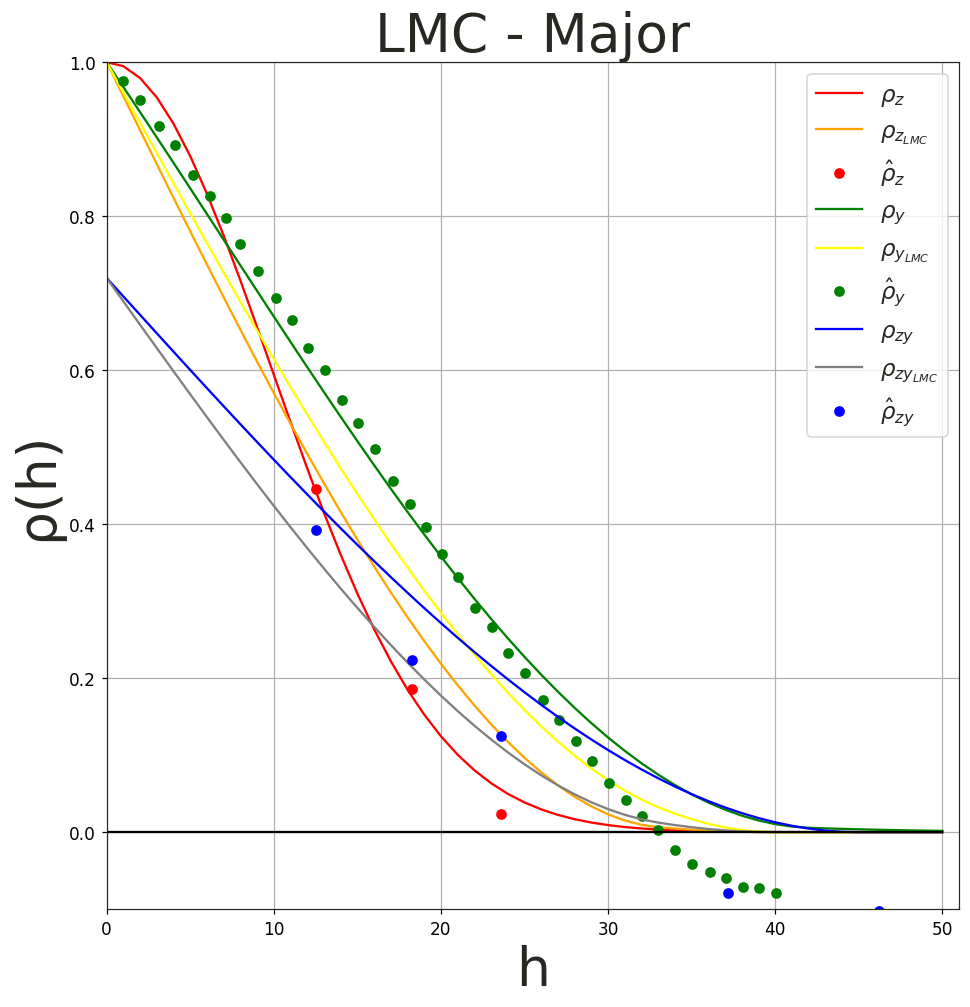

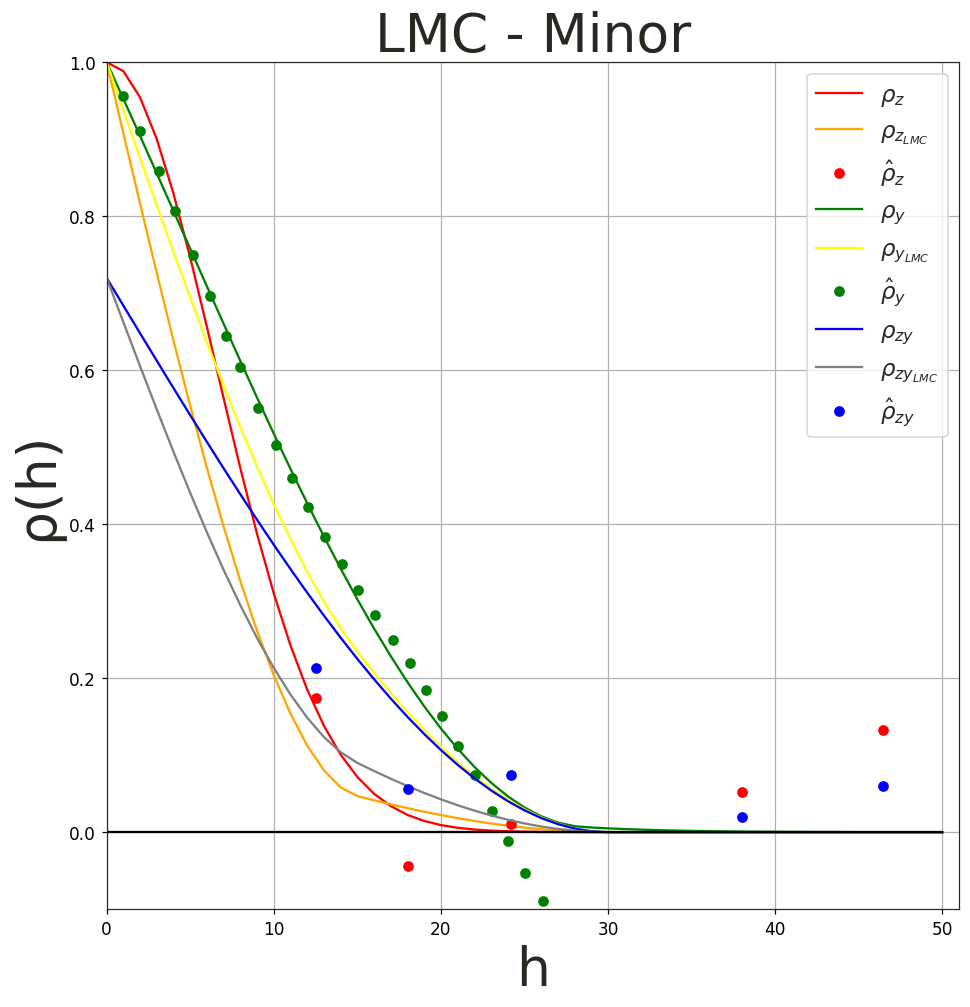

In [22]:
varg_type = 2  # See Correlogram Functions
for Dir in Directions:
    for h in range(0, 51):
        cy[h] = C_Y(
            np.array([h], dtype=float), np.array([h], dtype=float), varg_type
        ).item()
        cz_True[h] = C_Z(
            np.array([h], dtype=float), np.array([h], dtype=float), varg_type
        ).item()
        czy[h] = C_ZY(
            np.array([h], dtype=float), np.array([h], dtype=float), varg_type, corr
        ).item()
        cy_LMC[h] = C_Y_LMC(
            np.array([h], dtype=float), np.array([h], dtype=float), varg_type
        ).item()
        cz_LMC[h] = C_Z_LMC(
            np.array([h], dtype=float), np.array([h], dtype=float), varg_type
        ).item()
        czy_LMC[h] = C_ZY_LMC(
            np.array([h], dtype=float), np.array([h], dtype=float), varg_type, corr
        ).item()
    Vargs = [cz_True, cy, czy]
    LMCS = [cz_LMC, cy_LMC, czy_LMC]
    fig, axes = plt.subplots(1, 1, figsize=(10, 10))
    for i in range(0, 3):
        var = locals()[f"varcalcfl_{i + 1}"]
        axes.plot(H, Vargs[i], color=colors[i], label=labels_2[i])
        axes.plot(H, LMCS[i], color=colors_lmc[i], label=labels_lmc[i])
        axes.plot(
            var["Lag Distance"][var["Variogram Index"] == (varg_type - 1)],
            Sill_vals[i]
            - var["Variogram Value"][var["Variogram Index"] == (varg_type - 1)],
            "o",
            color=colors[i],
            label=labels_1[i],
        )

    axes.plot(H, ones, color="Black")
    axes.grid()
    plt.xlim(0, 51)
    plt.ylim(-0.1, 1)
    plt.ylabel("\u03c1(h)", size=35)
    plt.xlabel("h", size=35)
    plt.title(f"LMC - {Dir}", size=35)
    axes.legend(loc="best", prop={"size": 15})
    varg_type = varg_type + 1

## Kriging

### Data Statistics

In [23]:
Mean_Z = np.average(datafl["Primary"])
STD_Z = 1.0

In [24]:
Mean_Y = np.average(datafl["Secondary"])
STD_Y = 1.0

In [25]:
corr = np.corrcoef(datafl["Primary"], datafl["Secondary"])[0, 1]

### Create a KDTree to Quickly Get Nearest Points

In [26]:
from sklearn.neighbors import KDTree

In [27]:
datafl_XY = datafl[["X", "Y"]].values
tree = KDTree(datafl_XY)

In [28]:
Pred_grid_xy = np.array([x, y]).T

In [29]:
# Primary Data Search for Kriging
k = 60  # number of data to use
X_Y = np.zeros((len(x), k, 2))
X_Y_Star = np.zeros((len(x), k, 2))
closematrix_Primary = np.zeros((len(x), k))
closematrix_Secondary = np.zeros((len(x), k))
neardistmatrix = np.zeros((len(x), k))
for i in range(0, len(x)):
    nearest_dist, nearest_ind = tree.query(Pred_grid_xy[i : i + 1, :], k=k)
    a = nearest_ind.ravel()
    group = datafl.iloc[a, :]
    closematrix_Primary[i, :] = group["Primary"]
    closematrix_Secondary[i, :] = group["Secondary"]
    neardistmatrix[i, :] = nearest_dist
    X_Y[i, :, :] = group[["X", "Y"]]

In [30]:
datafl_XY_2nd = datafl_sec[["X", "Y"]].values
tree_2nd = KDTree(datafl_XY_2nd)

In [31]:
# Secondary Data Search for CoKriging
k = k  # number of neighbours
X_Y_2nd = np.zeros((len(x), k, 2))
closematrix_Secondary_2nd = np.zeros((len(x), k))
for i in range(0, len(x)):
    nearest_dist, nearest_ind = tree_2nd.query(Pred_grid_xy[i : i + 1, :], k=k)
    a = nearest_ind.ravel()
    group = datafl_sec.iloc[a, :]
    closematrix_Secondary_2nd[i, :] = group["Secondary"]
    X_Y_2nd[i, :, :] = group[["X", "Y"]]

### Simple Kriging

In [32]:
s_m = 0
sm_idx = []
est_SK = np.zeros(shape=(len(x)))
for z in tqdm(range(len(x)), disable=True):
    Kriging_Matrix = np.zeros(shape=((k, k)))
    # h = distance_matrix(X_Y[z,:,:].tolist(),X_Y[z,:,:].tolist())
    # C_ZZ
    Kriging_Matrix = C_Z(X_Y[z, :, :], X_Y[z, :, :], 0)
    # Set up Right Hand Side
    # print(Kriging_Matrix.reshape(((k)),((k))))
    r = np.zeros(shape=(k))
    k_weights = r
    # RHS #C_z*
    r = C_Z(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1)
    Kriging_Matrix.reshape((k), (k))
    # Calculate Kriging Weights
    try:
        k_weights = np.linalg.solve(Kriging_Matrix, r)
    except np.linalg.LinAlgError:
        s_m = s_m + 1
        sm_idx.append(z)
        k_weights = np.linalg.pinv(Kriging_Matrix) @ r
    # Start Est at zero
    est_SK[z] = 0
    # add in mean_z
    est_SK[z] = est_SK[z] + Mean_Z
    for i in range(0, k):
        # add in Z_i
        est_SK[z] = est_SK[z] + k_weights[i] * (closematrix_Primary[z, i] - Mean_Z)

### Full Cokriging

In [33]:
cz = np.zeros(shape=(k, k))
czy = np.zeros(shape=(k, k))
czy_2 = np.zeros(shape=(k, k))
cy = np.zeros(shape=(k, k))
s_m = 0
sm_idx = []
est_Full_CCK = np.zeros(shape=(len(x)))
for z in tqdm(range(len(x)), disable=True):
    Kriging_Matrix = np.zeros(shape=((k * 2), (k * 2)))
    # C_ZZ
    cz = C_Z_LMC(X_Y[z, :, :], X_Y[z, :, :], 0)
    # C_ZY
    czy = C_ZY_LMC(X_Y[z, :, :], X_Y_2nd[z, :, :], 0, corr)
    czy_2 = C_ZY_LMC(X_Y_2nd[z, :, :], X_Y[z, :, :], 0, corr)
    # C_YY
    cy = C_Y_LMC(X_Y_2nd[z, :, :], X_Y_2nd[z, :, :], 0)
    Kriging_Matrix = np.vstack((np.hstack((cz, czy)), np.hstack((czy.T, cy))))
    # print(Kriging_Matrix)
    # Set up Right Hand Sides
    r = np.zeros(shape=(k * 2))
    k_weights = np.zeros(shape=(k * 2))
    # RHS #C_z*
    r[0:k] = C_Z_LMC(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1)
    # RHS #C_zy*
    r[k : k * 2] = C_ZY_LMC(X_Y_2nd[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1, corr)
    # Calculate Kriging Weights
    try:
        k_weights = np.linalg.solve(Kriging_Matrix, r)
    except np.linalg.LinAlgError:
        s_m = s_m + 1
        sm_idx.append(z)
        k_weights = np.linalg.pinv(Kriging_Matrix) @ r
    # Start Est at zero
    est_Full_CCK[z] = 0
    # add in mean_z
    est_Full_CCK[z] = est_Full_CCK[z] + Mean_Z
    for i in range(0, k):
        # add in Z_i
        est_Full_CCK[z] = (
            est_Full_CCK[z]
            + k_weights[i] * (closematrix_Primary[z, i] - Mean_Z) / STD_Z
        )
        # add in Y_i
        est_Full_CCK[z] = (
            est_Full_CCK[z]
            + k_weights[i + k] * (closematrix_Secondary_2nd[z, i] - Mean_Y) / STD_Y
        )

### Simple Collocated Cokriging - MM1

In [34]:
s_m = 0
sm_idx = []
est_MM1 = np.zeros(shape=(len(x)))
for z in tqdm(range(len(x)), disable=True):
    Kriging_Matrix = np.zeros(shape=((k + 1), (k + 1)))
    # C_ZZ
    Kriging_Matrix[0:k, 0:k] = C_Z(X_Y[z, :, :], X_Y[z, :, :], 0)
    # Set up Right Hand Side
    # print(Kriging_Matrix.reshape(((2*k)+1),((2*k)+1)))
    r = np.zeros(shape=(k + 1))
    k_weights = np.zeros(shape=(k))
    # RHS #C_z*
    r[0:k] = C_Z(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1)
    # RHS corr
    r[k] = corr
    # c_zy
    Kriging_Matrix[k, 0 : k + 1] = r * corr
    Kriging_Matrix[0 : k + 1, k] = r * corr
    Kriging_Matrix[k, k] = 1
    # Calculate Kriging Weights
    try:
        k_weights = np.linalg.solve(Kriging_Matrix, r)
    except np.linalg.LinAlgError:
        s_m = s_m + 1
        sm_idx.append(z)
        k_weights = np.linalg.pinv(Kriging_Matrix) @ r
    # Start Est at zero
    est_MM1[z] = 0
    # add in mean_z
    est_MM1[z] = est_MM1[z] + Mean_Z
    # add in the Y_0
    est_MM1[z] = (
        est_MM1[z] + k_weights[k] * (datafl_sec["Secondary"][z] - Mean_Y) / STD_Y
    )
    for i in range(0, k):
        # add in Z_i
        est_MM1[z] = (
            est_MM1[z] + k_weights[i] * (closematrix_Primary[z, i] - Mean_Z) / STD_Z
        )

### Simple Collocated Cokriging - MM2

In [35]:
est_MM2 = np.zeros(shape=(len(x)))
s_m = 0
sm_idx = []
for z in tqdm(range(len(x)), disable=True):
    Kriging_Matrix = np.zeros(shape=((k + 1), (k + 1)))
    # C_ZZ
    Kriging_Matrix[0:k, 0:k] = C_Z_MM2(X_Y[z, :, :], X_Y[z, :, :], 0, corr)
    # Set up Right Hand Side
    # print(Kriging_Matrix.reshape(((2*k)+1),((2*k)+1)))
    r = np.zeros(shape=(k + 1))
    k_weights = np.zeros(shape=(k))
    # RHS #C_z*
    r[0:k] = C_Z_MM2(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1, corr)
    # RHS corr
    r[k] = corr
    # c_zy
    Kriging_Matrix[k, 0:k] = (
        C_Y(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1) * corr
    )
    Kriging_Matrix[0:k, k] = (
        C_Y(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1) * corr
    )
    Kriging_Matrix[k, k] = 1
    # Calculate Kriging Weights
    try:
        k_weights = np.linalg.solve(Kriging_Matrix, r)
    except np.linalg.LinAlgError:
        s_m = s_m + 1
        sm_idx.append(z)
        k_weights = np.linalg.pinv(Kriging_Matrix) @ r
    # Start Est at zero
    est_MM2[z] = 0
    # add in mean_z
    est_MM2[z] = est_MM2[z] + Mean_Z
    # add in the Y_0
    est_MM2[z] = (
        est_MM2[z] + k_weights[k] * (datafl_sec["Secondary"][z] - Mean_Y) / STD_Y
    )
    for i in range(0, k):
        # add in Z_i
        est_MM2[z] = (
            est_MM2[z] + k_weights[i] * (closematrix_Primary[z, i] - Mean_Z) / STD_Z
        )

### Intrinsic Collocated Cokriging - MM1

In [36]:
s_m = 0
sm_idx = []
cz = np.zeros(shape=(k, k))
czy = np.zeros(shape=(k, k))
cy = np.zeros(shape=(k, k))
est_icck_MM1 = np.zeros(shape=(len(x)))
for z in tqdm(range(len(x)), disable=True):
    Kriging_Matrix = np.zeros(shape=((k * 2 + 1), (k * 2 + 1)))
    # C_ZZ
    cz = C_Z(X_Y[z, :, :], X_Y[z, :, :], 0)
    # C_ZY
    czy = C_Z(X_Y[z, :, :], X_Y[z, :, :], 0) * corr
    # C_YY
    cy = C_Z(X_Y[z, :, :], X_Y[z, :, :], 0)
    # Set up Right Hand Side
    Kriging_Matrix[0 : k * 2, 0 : k * 2] = np.vstack(
        (np.hstack((cz, czy)), np.hstack((czy.T, cy)))
    )
    # print(Kriging_Matrix.reshape(((2*k)+1),((2*k)+1)))
    r = np.zeros(shape=(k * 2) + 1)
    k_weights = r
    # RHS #C_z*
    r[0:k] = C_Z(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1)
    # RHS #C_yz*
    r[k : k * 2] = C_Z(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1) * corr
    # RHS corr
    r[k * 2] = corr
    # c_zy
    Kriging_Matrix[k * 2, 0:k] = (
        C_Z(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1) * corr
    )
    Kriging_Matrix[0:k, k * 2] = (
        C_Z(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1) * corr
    )
    # c_z
    Kriging_Matrix[k * 2, k : k * 2] = C_Z(
        X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1
    )
    Kriging_Matrix[k : k * 2, k * 2] = C_Z(
        X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1
    )
    Kriging_Matrix[k * 2, k * 2] = 1
    # Calculate Kriging Weights
    try:
        k_weights = np.linalg.solve(Kriging_Matrix, r)
    except np.linalg.LinAlgError:
        s_m = s_m + 1
        sm_idx.append(z)
        k_weights = np.linalg.pinv(Kriging_Matrix) @ r
    # Start Est at zero
    est_icck_MM1[z] = 0
    # add in mean_z
    est_icck_MM1[z] = est_icck_MM1[z] + Mean_Z
    # add in the Y_0
    est_icck_MM1[z] = (
        est_icck_MM1[z]
        + k_weights[k * 2] * (datafl_sec["Secondary"][z] - Mean_Y) / STD_Y
    )
    for i in range(0, k):
        # add in Z_i
        est_icck_MM1[z] = (
            est_icck_MM1[z]
            + k_weights[i] * (closematrix_Primary[z, i] - Mean_Z) / STD_Z
        )
        # add in Y_i
        est_icck_MM1[z] = (
            est_icck_MM1[z]
            + k_weights[i + k] * (closematrix_Secondary[z, i] - Mean_Y) / STD_Y
        )

### Intrinsic Collocated Cokriging - MM2

In [37]:
s_m = 0
sm_idx = []
cz = np.zeros(shape=(k, k))
czy = np.zeros(shape=(k, k))
cy = np.zeros(shape=(k, k))
est_icck_MM2 = np.zeros(shape=(len(x)))
for z in tqdm(range(len(x)), disable=True):
    Kriging_Matrix = np.zeros(shape=((k * 2 + 1), (k * 2 + 1)))
    # C_ZZ
    # 1
    cz = C_Z_MM2(X_Y[z, :, :], X_Y[z, :, :], 0, corr)
    # C_ZY
    # 2,#3
    czy = corr * C_Y(X_Y[z, :, :], X_Y[z, :, :], 0)
    # C_YY
    # 4
    cy = C_Y(X_Y[z, :, :], X_Y[z, :, :], 0)
    # Set up Right Hand Side
    # print(Kriging_Matrix.reshape(((2*k)+1),((2*k)+1)))
    Kriging_Matrix[0 : k * 2, 0 : k * 2] = np.vstack(
        (np.hstack((cz, czy)), np.hstack((czy.T, cy)))
    )
    r = np.zeros(shape=(k * 2) + 1)
    k_weights = r
    # RHS #C_z*
    # 5
    r[0:k] = C_Z_MM2(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1, corr)
    # RHS #C_yz*
    # 6
    r[k : k * 2] = C_Y(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1) * corr
    # RHS corr
    # 7
    r[k * 2] = corr
    # c_zy
    # 8
    Kriging_Matrix[k * 2, 0:k] = (
        C_Y(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1) * corr
    )
    Kriging_Matrix[0:k, k * 2] = (
        C_Y(X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1) * corr
    )
    # c_y
    # 9
    Kriging_Matrix[k * 2, k : k * 2] = C_Y(
        X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1
    )
    Kriging_Matrix[k : k * 2, k * 2] = C_Y(
        X_Y[z, :, :], np.tile(Pred_grid_xy[z], (k, 1)), 1
    )
    Kriging_Matrix[k * 2, k * 2] = 1
    # Kriging_Matrix.reshape(((2*k)+1),((2*k)+1))
    # Calculate Kriging Weights
    try:
        k_weights = np.linalg.solve(Kriging_Matrix, r)
    except np.linalg.LinAlgError:
        s_m = s_m + 1
        sm_idx.append(z)
        k_weights = np.linalg.pinv(Kriging_Matrix) @ r
    # Start Est at zero
    est_icck_MM2[z] = 0
    # add in mean_z
    est_icck_MM2[z] = est_icck_MM2[z] + Mean_Z
    # add in the Y_0
    est_icck_MM2[z] = (
        est_icck_MM2[z]
        + k_weights[k * 2] * (datafl_sec["Secondary"][z] - Mean_Y) / STD_Y
    )
    for i in range(0, k):
        # add in Z_i
        est_icck_MM2[z] = (
            est_icck_MM2[z]
            + k_weights[i] * (closematrix_Primary[z, i] - Mean_Z) / STD_Z
        )
        # add in Y_i
        est_icck_MM2[z] = (
            est_icck_MM2[z]
            + k_weights[i + k] * (closematrix_Secondary[z, i] - Mean_Y) / STD_Y
        )

### Results

In [38]:
# Setup Dictionary of Results
ktypes = ["SK", "SCK", "SCCK_MMI", "SCCK_MMII", "ICCK_MMI", "ICCK_MMII"]
k_est = [
    est_SK,
    est_Full_CCK,
    est_MM1,
    est_MM2,
    est_icck_MM1,
    est_icck_MM2,
]
assert np.isfinite(k_est).all(), "Kriging estimates must be finite."
ktypes_vals_dict = {}
j = 0
for i in ktypes:
    ktypes_vals_dict[i] = {
        "Estimate": k_est[j],
        "RMSE": np.sqrt(mean_squared_error(k_est[j], truth["Primary"])),
        "Mean": np.mean(k_est[j]),
        "Variance": np.var(k_est[j]),
    }
    j = j + 1

# The distance correction affects SCCK MMII; other methods retain their reference RMSEs.
reference_rmse = {
    "SK": 0.6972516186,
    "SCK": 0.5434166615,
    "SCCK_MMI": 0.6215185501,
    "ICCK_MMI": 0.5542006197,
    "ICCK_MMII": 0.5444617389,
}
for method, expected in reference_rmse.items():
    np.testing.assert_allclose(ktypes_vals_dict[method]["RMSE"], expected, atol=1e-8)

#### Pixelplt

In [39]:
# Setup Subplot Function
def plot_axe(figsize):
    # Set up Plotting Grid
    axes = []
    fig = plt.figure(constrained_layout=True, figsize=figsize)
    gs = gridspec.GridSpec(3, 4, figure=fig)
    gs.update(wspace=0.01, hspace=0.01)
    k = 0
    for i in range(0, 3):
        for j in range(1, 3):
            k = k + 1
            ax = locals()[f"ax{k}"] = plt.subplot(gs[i, (j - 1) * 2 : j * 2])
            axes.append(ax)
    return fig, gs, axes

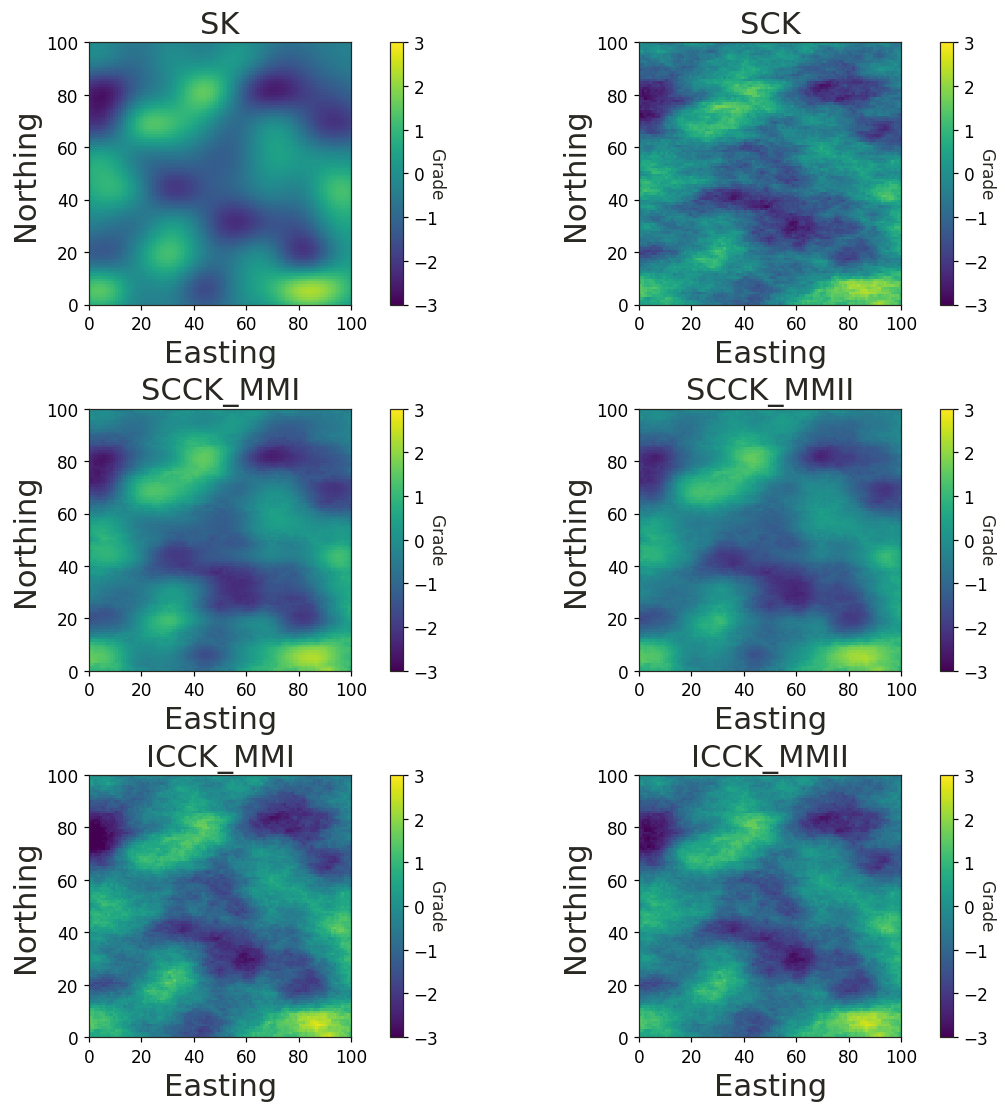

In [40]:
fig, gs, axes = plot_axe(figsize=(10, 10))
ax_i = 0
for i in ktypes:
    gridd["Estimate"] = ktypes_vals_dict[i]["Estimate"]
    gridded = np.reshape(
        gridd.sort_values(by=["Y", "X"], axis=0, ascending=True)["Estimate"].values,
        [100, 100],
        order="C",
    )
    ax = axes[ax_i]
    plt_1 = ax.imshow(
        gridded,
        origin="lower",
        extent=[XMIN, XMAX, YMIN, YMAX],
        aspect="equal",
        interpolation="none",
        vmin=SMIN,
        vmax=SMAX,
        cmap="viridis",
    )
    ax.set_title(f"{i}", size=20)
    ax.set_xlabel("Easting", size=20)
    ax.set_ylabel("Northing", size=20)
    cbar = plt.colorbar(plt_1, ax=ax)
    cbar.set_label("Grade", rotation=270)
    ax_i = ax_i + 1
plt.show()

#### Data Reproduction

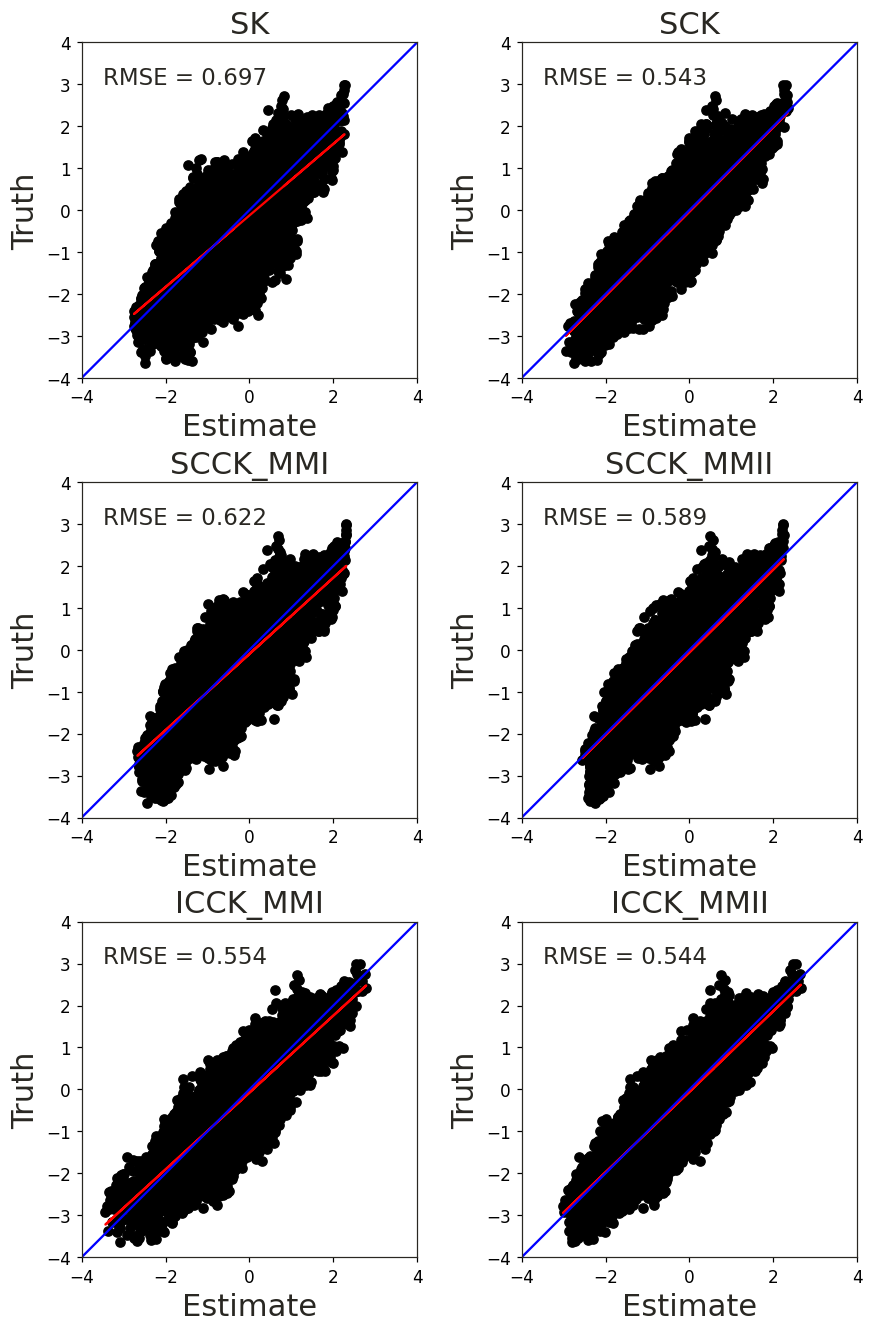

In [41]:
fig, gs, axes = plot_axe(figsize=(8, 12))
ax_i = 0
for i in ktypes:
    ax = axes[ax_i]
    ax.scatter(ktypes_vals_dict[i]["Estimate"], truth["Primary"], color="Black")
    ax.plot(
        ktypes_vals_dict[i]["Estimate"],
        np.poly1d(np.polyfit(ktypes_vals_dict[i]["Estimate"], truth["Primary"], 1))(
            ktypes_vals_dict[i]["Estimate"]
        ),
        color="Red",
    )
    ax.set_title(f"{i}", size=20)
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    x_45 = np.linspace(*ax.get_xlim())
    ax.plot(x_45, x_45, color="blue")
    ax.set_xlabel("Estimate", size=20)
    ax.set_ylabel("Truth", size=20)
    ax.set_aspect("equal", "box")
    ax.text(
        -3.5,
        3.0,
        "RMSE = {:.3f}".format(ktypes_vals_dict[i]["RMSE"]),
        size=15,
    )
    ax_i = ax_i + 1
plt.show()